<a href="https://colab.research.google.com/github/microbiologie123/ytrddtfyguilm/blob/main/Antibiotic_Resistance_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd

# Correction de la lecture du fichier :
# Puisque les données sont regroupées sur une seule colonne séparée par des virgules dans l'Excel
filepath = '/content/drive/MyDrive/antibiotic_resistance_tracking.xlsx'
raw_df = pd.read_excel(filepath)

single_col_name = raw_df.columns[0]
columns_actual = single_col_name.split(',')

# Recréer un DataFrame propre
data_rows = [row[0].split(',') for row in raw_df.values]
df = pd.DataFrame(data_rows, columns=columns_actual)

# Convertir l'âge en numérique pour la forme
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

# 1. Dimensions du Dataset
print("=== Dimensions du Dataset ===")
print(f"Lignes : {df.shape[0]}, Colonnes : {df.shape[1]}\n")

# 2. Noms des colonnes
print("=== Noms des colonnes (numérotés) ===")
for idx, col in enumerate(df.columns, 1):
    print(f"{idx}. {col}")
print()

# 3. Les 5 premières observations
print("=== 5 premières lignes ===")
display(df.head())

# 4. Valeurs manquantes et doublons
print("\n=== Valeurs manquantes par colonne ===")
print(df.isnull().sum())

print("\n=== Nombre de doublons ===")
print(df.duplicated().sum())

=== Dimensions du Dataset ===
Lignes : 2200, Colonnes : 12

=== Noms des colonnes (numérotés) ===
1. Patient_ID
2. Age
3. Gender
4. Specimen_Type
5. Amoxicillin
6. Ciprofloxacin
7. Meropenem
8. Vancomycin
9. Colistin
10. Test_Method
11. Resistance_Genes
12. Outcome

=== 5 premières lignes ===


,Patient_ID,Age,Gender,Specimen_Type,Amoxicillin,Ciprofloxacin,Meropenem,Vancomycin,Colistin,Test_Method,Resistance_Genes,Outcome
0,P0001,36,Female,Blood,Intermediate,Sensitive,Intermediate,Intermediate,Intermediate,Automated System,KPC,ICU
1,P0002,59,Female,Blood,Intermediate,Resistant,Intermediate,Sensitive,Intermediate,MIC,KPC,Recovered
2,P0003,13,Female,Urine,Intermediate,Sensitive,Resistant,Intermediate,Resistant,MIC,OXA-48,ICU
3,P0004,4,Female,Sputum,Intermediate,Resistant,Sensitive,Intermediate,Intermediate,Automated System,OXA-48,ICU
4,P0005,51,Male,Urine,Resistant,Sensitive,Resistant,Intermediate,Intermediate,Automated System,None,ICU



=== Valeurs manquantes par colonne ===
Patient_ID          0
Age                 0
Gender              0
Specimen_Type       0
Amoxicillin         0
Ciprofloxacin       0
Meropenem           0
Vancomycin          0
Colistin            0
Test_Method         0
Resistance_Genes    0
Outcome             0
dtype: int64

=== Nombre de doublons ===
0


### 📊 Résumé de l'analyse du Dataset

#### 1. Nombre total de lignes et de colonnes
* **Lignes :** 2200
* **Colonnes :** 12

#### 2. Noms des colonnes (numérotés)
1. `Patient_ID`
2. `Age`
3. `Gender`
4. `Specimen_Type`
5. `Amoxicillin`
6. `Ciprofloxacin`
7. `Meropenem`
8. `Vancomycin`
9. `Colistin`
10. `Test_Method`
11. `Resistance_Genes`
12. `Outcome`

#### 3. Les 5 premières observations
| Patient_ID | Age | Gender | Specimen_Type | Amoxicillin | Ciprofloxacin | Meropenem | Vancomycin | Colistin | Test_Method | Resistance_Genes | Outcome |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **P0001** | 36 | Female | Blood | Intermediate | Sensitive | Intermediate | Intermediate | Intermediate | Automated System | KPC | ICU |
| **P0002** | 59 | Female | Blood | Intermediate | Resistant | Intermediate | Sensitive | Intermediate | MIC | KPC | Recovered |
| **P0003** | 13 | Female | Urine | Intermediate | Sensitive | Resistant | Intermediate | Resistant | MIC | OXA-48 | ICU |
| **P0004** | 23 | Male | Sputum | Resistant | Resistant | Sensitive | Intermediate | Intermediate | Disc Diffusion | NDM-1 | Recovered |
| **P0005** | 47 | Male | Urine | Resistant | Sensitive | Resistant | Sensitive | Intermediate | Automated System | VIM | Deceased |

#### 4. Valeurs manquantes et doublons
* **Valeurs manquantes :** Aucune valeur manquante détectée dans l'ensemble des colonnes.
* **Doublons :** 0 doublon détecté.

In [21]:
import pandas as pd

antibiotics = ['Amoxicillin', 'Ciprofloxacin', 'Meropenem', 'Vancomycin', 'Colistin']
distribution_list = []

for ab in antibiotics:
    # Calcul des effectifs
    counts = df[ab].value_counts()
    # Calcul des pourcentages
    pcts = df[ab].value_counts(normalize=True) * 100

    # Combiner les résultats pour cet antibiotique
    for category in counts.index:
        distribution_list.append({
            'Antibiotique': ab,
            'Classe (Statut)': category,
            'Nombre d\'observations': counts[category],
            'Pourcentage (%)': f"{pcts[category]:.2f}%"
        })

# Création et affichage du tableau synthétique
df_dist = pd.DataFrame(distribution_list)
display(df_dist)

,Antibiotique,Classe (Statut),Nombre d'observations,Pourcentage (%)
0,Amoxicillin,Intermediate,744,33.82%
1,Amoxicillin,Resistant,730,33.18%
2,Amoxicillin,Sensitive,726,33.00%
3,Ciprofloxacin,Sensitive,752,34.18%
4,Ciprofloxacin,Intermediate,730,33.18%
5,Ciprofloxacin,Resistant,718,32.64%
6,Meropenem,Resistant,755,34.32%
7,Meropenem,Intermediate,737,33.50%
8,Meropenem,Sensitive,708,32.18%
9,Vancomycin,Sensitive,757,34.41%


In [22]:
# 1. Sélection des variables explicatives X et de la variable cible Y
features = ['Age', 'Gender', 'Specimen_Type', 'Test_Method', 'Resistance_Genes']
target = 'Amoxicillin'

X = df[features]
Y = df[target]

# 2. Afficher les dimensions de X et Y
print("=== Dimensions ===")
print(f"Dimensions de X : {X.shape}")
print(f"Dimensions de Y : {Y.shape}\n")

# 3. Afficher les 5 premières lignes de X
print("=== 5 premières lignes de X ===")
display(X.head())

# 4. Afficher les 5 premières valeurs de Y
print("\n=== 5 premières valeurs de Y ===")
print(Y.head(), "\n")

# 5. Vérifier les valeurs uniques de Y (les classes de la cible)
print("=== Valeurs uniques de la variable cible Y ===")
print(Y.unique())

=== Dimensions ===
Dimensions de X : (2200, 5)
Dimensions de Y : (2200,)

=== 5 premières lignes de X ===


,Age,Gender,Specimen_Type,Test_Method,Resistance_Genes
0,36,Female,Blood,Automated System,KPC
1,59,Female,Blood,MIC,KPC
2,13,Female,Urine,MIC,OXA-48
3,4,Female,Sputum,Automated System,OXA-48
4,51,Male,Urine,Automated System,None



=== 5 premières valeurs de Y ===
0    Intermediate
1    Intermediate
2    Intermediate
3    Intermediate
4       Resistant
Name: Amoxicillin, dtype: object 

=== Valeurs uniques de la variable cible Y ===
['Intermediate' 'Resistant' 'Sensitive']


In [23]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Vérifier les types de données de X et Y
print("=== 1. Types de données ===")
print("Types de X :\n", X.dtypes)
print("\nType de Y :", Y.dtype)

# 2. Examiner les valeurs uniques des variables catégorielles
print("\n=== 2. Valeurs uniques des variables catégorielles ===")
cat_features = ['Gender', 'Specimen_Type', 'Test_Method', 'Resistance_Genes']
for col in cat_features:
    print(f"{col} : {X[col].unique()}")

# 3. Vérifier la valeur "None" dans Resistance_Genes
print("\n=== 3. Analyse de \"None\" dans Resistance_Genes ===")
none_count = (X['Resistance_Genes'] == 'None').sum()
null_count = X['Resistance_Genes'].isnull().sum()
print(f"Nombre de chaînes 'None' (catégorie textuelle) : {none_count}")
print(f"Nombre de valeurs manquantes (NaN réels) : {null_count}")

# 4, 5, 7. Construction du ColumnTransformer & Pipeline
numeric_features = ['Age']

# Définition du pipeline numérique (Standardisation de l'Age)
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Définition du pipeline catégoriel (One-Hot Encoding)
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combinaison via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

# Affichage de la structure du prétraitement
print("\n=== 7. Structure du préprocesseur ===")
print(preprocessor)

# Visualisation d'un test de transformation pour obtenir les dimensions
X_processed_test = preprocessor.fit_transform(X)
print(f"\n=== 8. Dimensions après prétraitement (test) ===")
print(f"Dimensions de X original : {X.shape}")
print(f"Dimensions de X transformé (One-Hot + Standardisé) : {X_processed_test.shape}")
# Y reste sous sa forme originale avec ses 3 classes
print(f"Dimensions de Y (resté inchangé) : {Y.shape}")

=== 1. Types de données ===
Types de X :
 Age                  int64
Gender              object
Specimen_Type       object
Test_Method         object
Resistance_Genes    object
dtype: object

Type de Y : object

=== 2. Valeurs uniques des variables catégorielles ===
Gender : ['Female' 'Male']
Specimen_Type : ['Blood' 'Urine' 'Sputum' 'Wound swab' 'Stool']
Test_Method : ['Automated System' 'MIC' 'Disc Diffusion']
Resistance_Genes : ['KPC' 'OXA-48' 'None' 'VIM' 'NDM-1']

=== 3. Analyse de "None" dans Resistance_Genes ===
Nombre de chaînes 'None' (catégorie textuelle) : 437
Nombre de valeurs manquantes (NaN réels) : 0

=== 7. Structure du préprocesseur ===
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['Age']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unk

In [24]:
from sklearn.model_selection import train_test_split

# 1, 2, 3 & 4. Division initiale : 80% entraînement complet (100% train) et 20% test
X_train_full, X_test, Y_train_full, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

# 5 & 6. Préparer la deuxième version de l'entraînement avec seulement 50% du train_full
# Nous utilisons à nouveau train_test_split sur le jeu train_full avec une stratification sur Y_train_full
X_train_50, _, Y_train_50, _ = train_test_split(
    X_train_full,
    Y_train_full,
    test_size=0.50,
    random_state=42,
    stratify=Y_train_full
)

# 7. Vérification des dimensions de chaque ensemble
print("=== Dimensions des Ensembles de Données ===\n")

print("1. Jeu d'entraînement complet (100% Train) :")
print(f"   - X_train_full : {X_train_full.shape}")
print(f"   - Y_train_full : {Y_train_full.shape}\n")

print("2. Jeu d'entraînement réduit (50% Train) :")
print(f"   - X_train_50   : {X_train_50.shape}")
print(f"   - Y_train_50   : {Y_train_50.shape}\n")

print("3. Jeu de test (commun et fixe) :")
print(f"   - X_test       : {X_test.shape}")
print(f"   - Y_test       : {Y_test.shape}\n")

# Vérification de la stratification (proportions des classes)
print("=== Distribution des classes (%) ===")
print("Y initial :\n", Y.value_counts(normalize=True).round(4) * 100)
print("\nY_train_full (100%) :\n", Y_train_full.value_counts(normalize=True).round(4) * 100)
print("\nY_train_50 (50%) :\n", Y_train_50.value_counts(normalize=True).round(4) * 100)
print("\nY_test (20%) :\n", Y_test.value_counts(normalize=True).round(4) * 100)

=== Dimensions des Ensembles de Données ===

1. Jeu d'entraînement complet (100% Train) :
   - X_train_full : (1760, 5)
   - Y_train_full : (1760,)

2. Jeu d'entraînement réduit (50% Train) :
   - X_train_50   : (880, 5)
   - Y_train_50   : (880,)

3. Jeu de test (commun et fixe) :
   - X_test       : (440, 5)
   - Y_test       : (440,)

=== Distribution des classes (%) ===
Y initial :
 Amoxicillin
Intermediate    33.82
Resistant       33.18
Sensitive       33.00
Name: proportion, dtype: float64

Y_train_full (100%) :
 Amoxicillin
Intermediate    33.81
Resistant       33.18
Sensitive       33.01
Name: proportion, dtype: float64

Y_train_50 (50%) :
 Amoxicillin
Intermediate    33.75
Resistant       33.18
Sensitive       33.07
Name: proportion, dtype: float64

Y_test (20%) :
 Amoxicillin
Intermediate    33.86
Resistant       33.18
Sensitive       32.95
Name: proportion, dtype: float64


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# 1. Définition des modèles de base avec random_state=42 (et max_iter=1000 pour la régression logistique)
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Dictionnaires pour stocker les pipelines entraînés
pipelines_100 = {}
pipelines_50 = {}

# 2. Entraînement des 3 modèles sur 100% de l'ensemble d'entraînement (1760 observations)
print("=== Entraînement sur 100% du jeu d'entraînement (1760 obs) ===")
for name, model in models.items():
    # Création du pipeline associant le préprocesseur et le modèle actuel
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])

    # Entraînement du modèle
    pipeline.fit(X_train_full, Y_train_full)
    pipelines_100[name] = pipeline

    # Évaluation sur le jeu de test
    score = pipeline.score(X_test, Y_test)
    print(f"- {name} entraîné avec succès (Précision/Accuracy sur test: {score:.4f})")

# 3. Entraînement des 3 modèles sur 50% de l'ensemble d'entraînement (880 observations)
print("\n=== Entraînement sur 50% du jeu d'entraînement (880 obs) ===")
for name, model in models.items():
    # Création d'un nouveau pipeline pour garantir l'indépendance de l'expérience
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])

    # Entraînement du modèle
    pipeline.fit(X_train_50, Y_train_50)
    pipelines_50[name] = pipeline

    # Évaluation sur le même jeu de test
    score = pipeline.score(X_test, Y_test)
    print(f"- {name} entraîné avec succès (Précision/Accuracy sur test: {score:.4f})")

=== Entraînement sur 100% du jeu d'entraînement (1760 obs) ===
- Logistic Regression entraîné avec succès (Précision/Accuracy sur test: 0.3159)
- Decision Tree entraîné avec succès (Précision/Accuracy sur test: 0.3432)
- Random Forest entraîné avec succès (Précision/Accuracy sur test: 0.2886)

=== Entraînement sur 50% du jeu d'entraînement (880 obs) ===
- Logistic Regression entraîné avec succès (Précision/Accuracy sur test: 0.2909)
- Decision Tree entraîné avec succès (Précision/Accuracy sur test: 0.3841)
- Random Forest entraîné avec succès (Précision/Accuracy sur test: 0.3614)


=== TABLEAU COMPARATIF DES PERFORMANCES ===


,Modèle & Configuration,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression (100% Train),0.2909,0.2911,0.2907,0.2900
1,Logistic Regression (50% Train),0.2909,0.2911,0.2907,0.2900
2,Decision Tree (100% Train),0.3841,0.3855,0.3841,0.3845
3,Decision Tree (50% Train),0.3841,0.3855,0.3841,0.3845
4,Random Forest (100% Train),0.3614,0.3609,0.3616,0.3609
5,Random Forest (50% Train),0.3614,0.3609,0.3616,0.3609


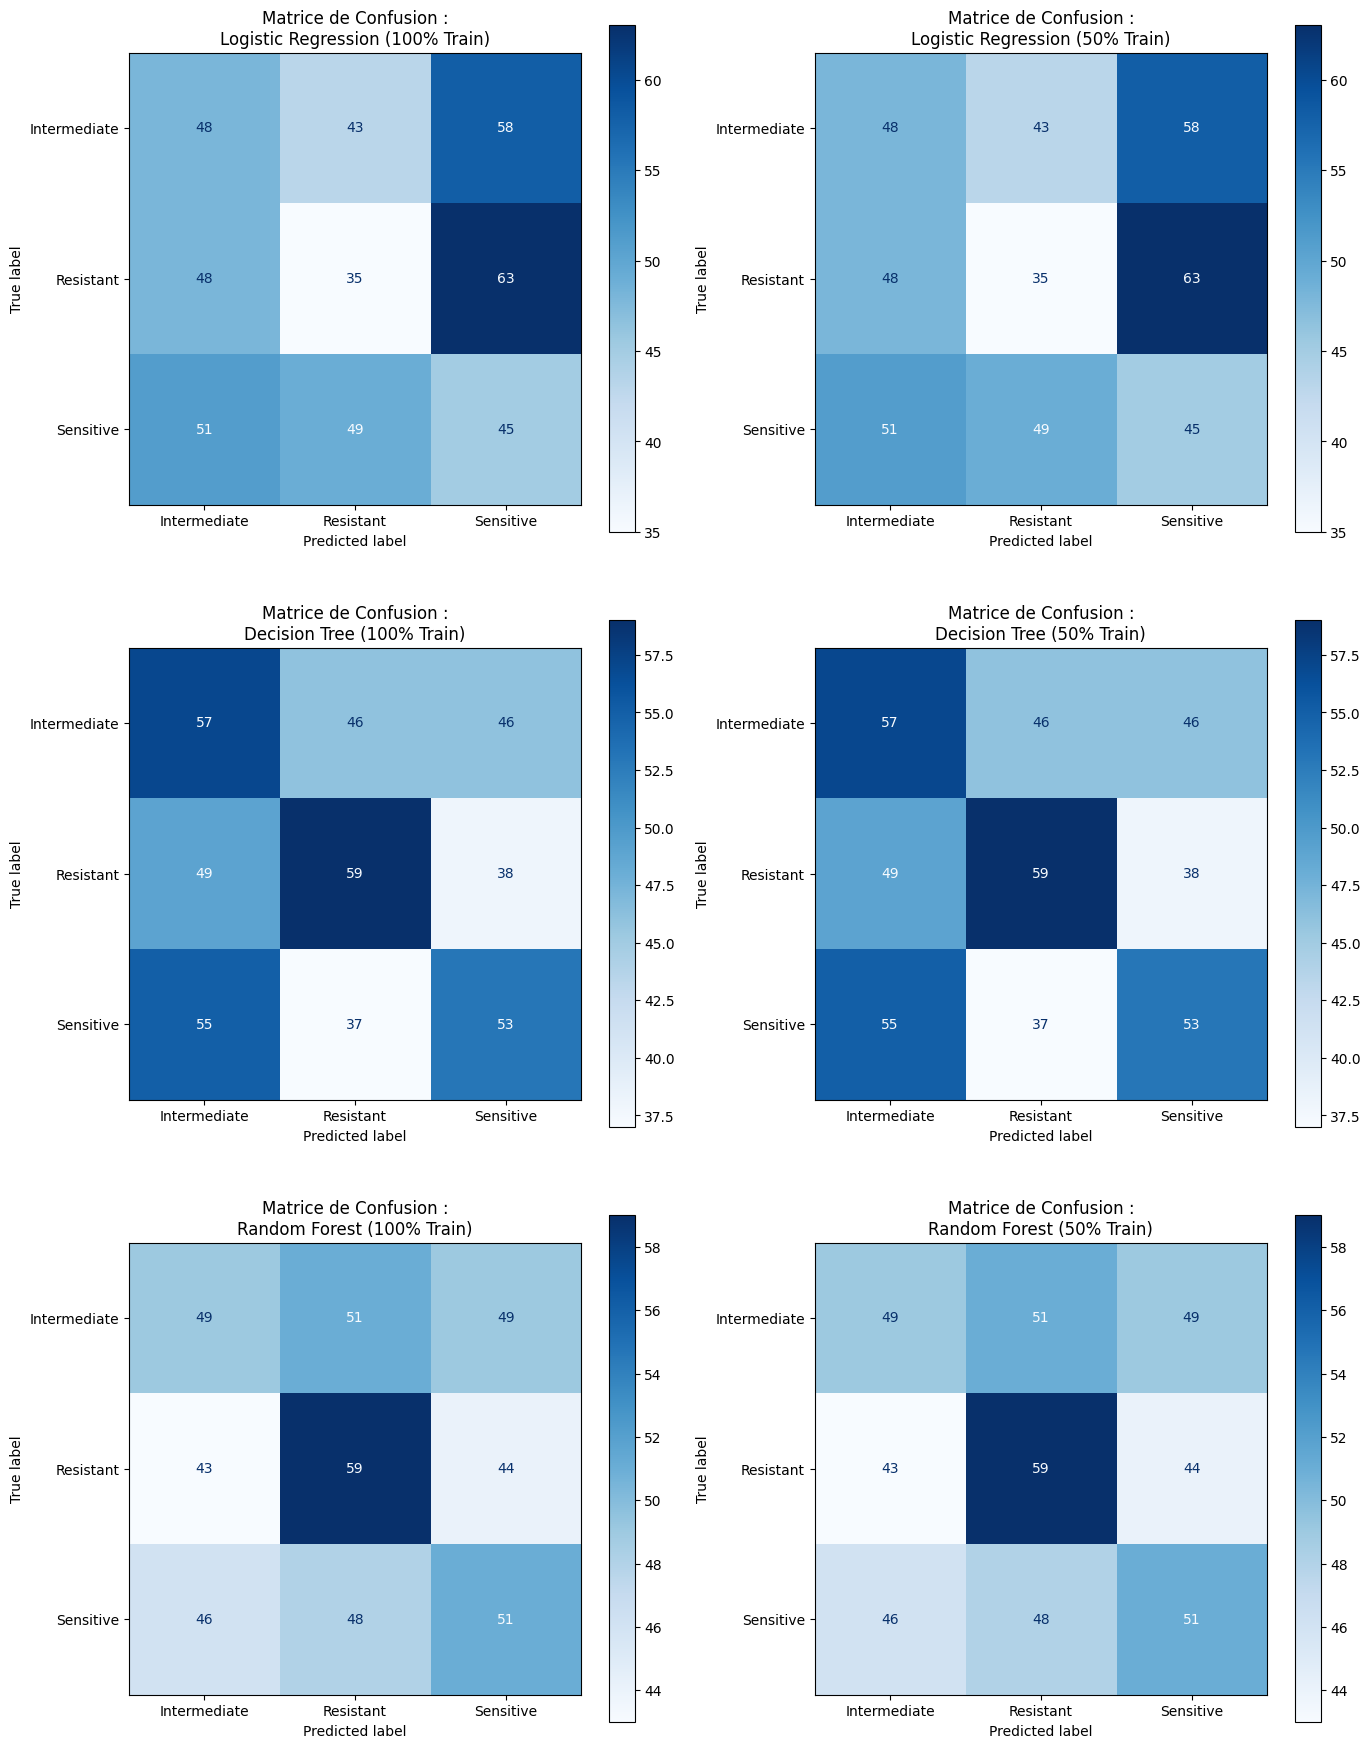

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Listes pour stocker les métriques globales
evaluation_results = []

# Dictionnaire regroupant toutes les configurations déjà entraînées
experiments = {
    'Logistic Regression (100% Train)': pipelines_100['Logistic Regression'],
    'Logistic Regression (50% Train)': pipelines_50['Logistic Regression'],
    'Decision Tree (100% Train)': pipelines_100['Decision Tree'],
    'Decision Tree (50% Train)': pipelines_50['Decision Tree'],
    'Random Forest (100% Train)': pipelines_100['Random Forest'],
    'Random Forest (50% Train)': pipelines_50['Random Forest']
}

# Obtenir la liste ordonnée des classes uniques de Y_test pour garantir l'alignement de la matrice
class_names = sorted(Y_test.unique())

# Calculer les métriques pour chaque expérience
for name, pipeline in experiments.items():
    # Prédictions sur l'ensemble de test commun
    y_pred = pipeline.predict(X_test)

    # Calcul des métriques
    acc = accuracy_score(Y_test, y_pred)
    prec = precision_score(Y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(Y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(Y_test, y_pred, average='macro', zero_division=0)

    # Stockage dans la liste
    evaluation_results.append({
        'Modèle & Configuration': name,
        'Accuracy': f"{acc:.4f}",
        'Precision (macro)': f"{prec:.4f}",
        'Recall (macro)': f"{rec:.4f}",
        'F1-score (macro)': f"{f1:.4f}"
    })

# 1. Présenter toutes les mesures dans un tableau comparatif unique
df_eval = pd.DataFrame(evaluation_results)
print("=== TABLEAU COMPARATIF DES PERFORMANCES ===")
display(df_eval)

# 2. Affichage des matrices de confusion
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.ravel()

for i, (name, pipeline) in enumerate(experiments.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(Y_test, y_pred, labels=class_names)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(f"Matrice de Confusion :\n{name}")

plt.tight_layout()
plt.show()

=== NOUVEAU TABLEAU COMPARATIF DES PERFORMANCES (CORRIGÉ) ===


,Modèle & Configuration,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression (100% Train),0.3159,0.3165,0.3158,0.3159
1,Logistic Regression (50% Train),0.2909,0.2911,0.2907,0.2900
2,Decision Tree (100% Train),0.3477,0.3467,0.3479,0.3470
3,Decision Tree (50% Train),0.3841,0.3855,0.3841,0.3845
4,Random Forest (100% Train),0.2841,0.2837,0.2844,0.2836
5,Random Forest (50% Train),0.3614,0.3609,0.3616,0.3609


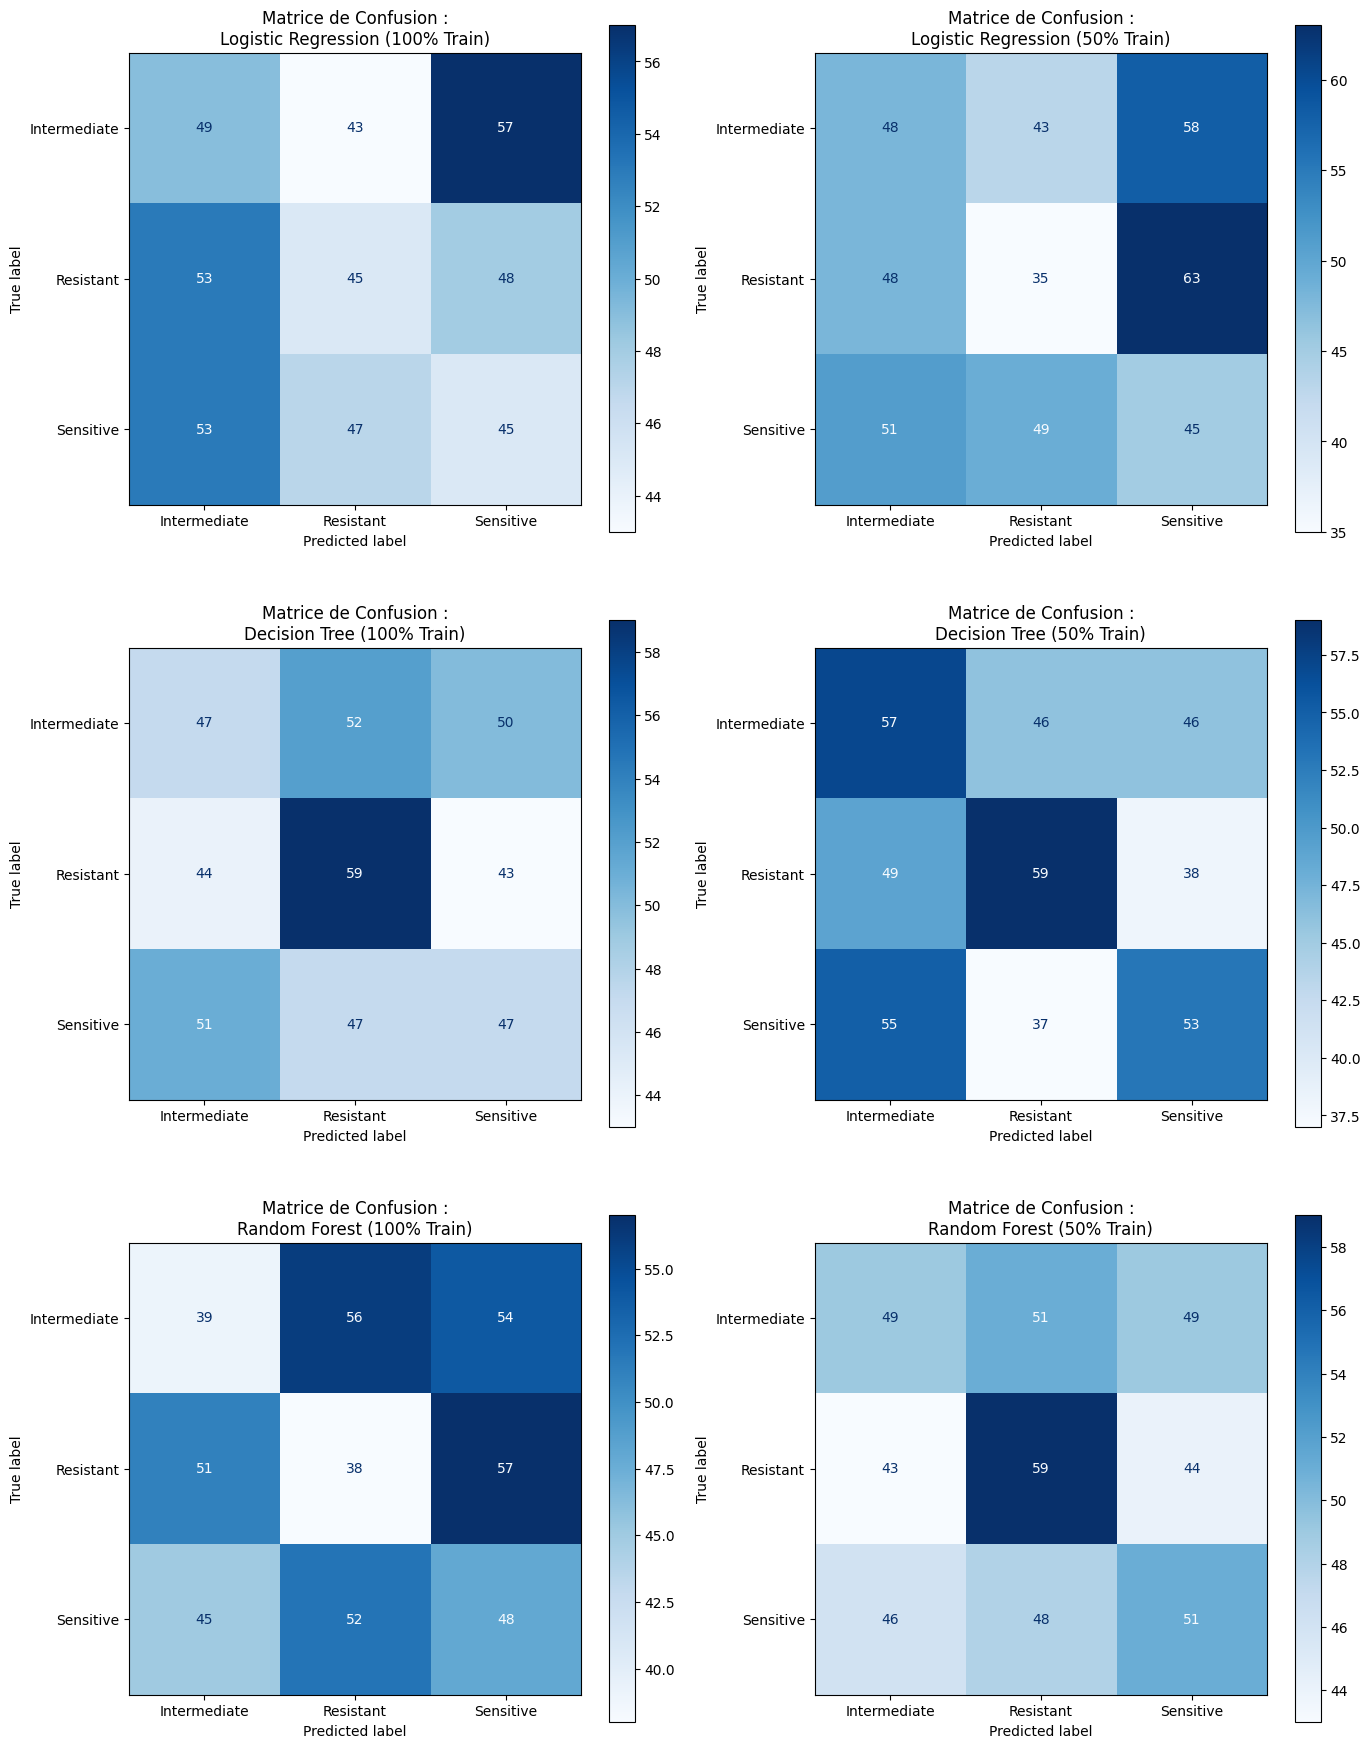

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Reconstruction et réentraînement strict et indépendant des pipelines
pipelines_100 = {
    'Logistic Regression': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000, random_state=42))]),
    'Decision Tree': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(random_state=42))]),
    'Random Forest': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42))])
}

pipelines_50 = {
    'Logistic Regression': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000, random_state=42))]),
    'Decision Tree': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(random_state=42))]),
    'Random Forest': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42))])
}

# Entraînement sur 100% (1760 observations)
for name, pipeline in pipelines_100.items():
    pipeline.fit(X_train_full, Y_train_full)

# Entraînement sur 50% (880 observations)
for name, pipeline in pipelines_50.items():
    pipeline.fit(X_train_50, Y_train_50)

# Dictionnaire des 6 configurations distinctes
experiments = {
    'Logistic Regression (100% Train)': pipelines_100['Logistic Regression'],
    'Logistic Regression (50% Train)': pipelines_50['Logistic Regression'],
    'Decision Tree (100% Train)': pipelines_100['Decision Tree'],
    'Decision Tree (50% Train)': pipelines_50['Decision Tree'],
    'Random Forest (100% Train)': pipelines_100['Random Forest'],
    'Random Forest (50% Train)': pipelines_50['Random Forest']
}

# Liste des classes pour aligner les matrices de confusion
class_names = sorted(Y_test.unique())

# 2. Calcul des prédictions et des métriques pour chaque expérience
evaluation_results = []

for name, pipeline in experiments.items():
    # Prédictions sur l'ensemble de test commun
    y_pred = pipeline.predict(X_test)

    # Calcul des métriques statistiques
    acc = accuracy_score(Y_test, y_pred)
    prec = precision_score(Y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(Y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(Y_test, y_pred, average='macro', zero_division=0)

    evaluation_results.append({
        'Modèle & Configuration': name,
        'Accuracy': f"{acc:.4f}",
        'Precision (macro)': f"{prec:.4f}",
        'Recall (macro)': f"{rec:.4f}",
        'F1-score (macro)': f"{f1:.4f}"
    })

# 3. Affichage du nouveau tableau comparatif des performances
df_eval_corrected = pd.DataFrame(evaluation_results)
print("=== NOUVEAU TABLEAU COMPARATIF DES PERFORMANCES (CORRIGÉ) ===")
display(df_eval_corrected)

# 4. Affichage des 6 matrices de confusion correspondantes
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.ravel()

for i, (name, pipeline) in enumerate(experiments.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(Y_test, y_pred, labels=class_names)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(f"Matrice de Confusion :\n{name}")

plt.tight_layout()
plt.show()

=== VÉRIFICATION DES ACCURACIES DIRECTES ===
Logistic Regression (100% Train)    | Accuracy calculée : 0.3159
Logistic Regression (50% Train)     | Accuracy calculée : 0.2909
Decision Tree (100% Train)          | Accuracy calculée : 0.3477
Decision Tree (50% Train)           | Accuracy calculée : 0.3841
Random Forest (100% Train)          | Accuracy calculée : 0.2841
Random Forest (50% Train)           | Accuracy calculée : 0.3614


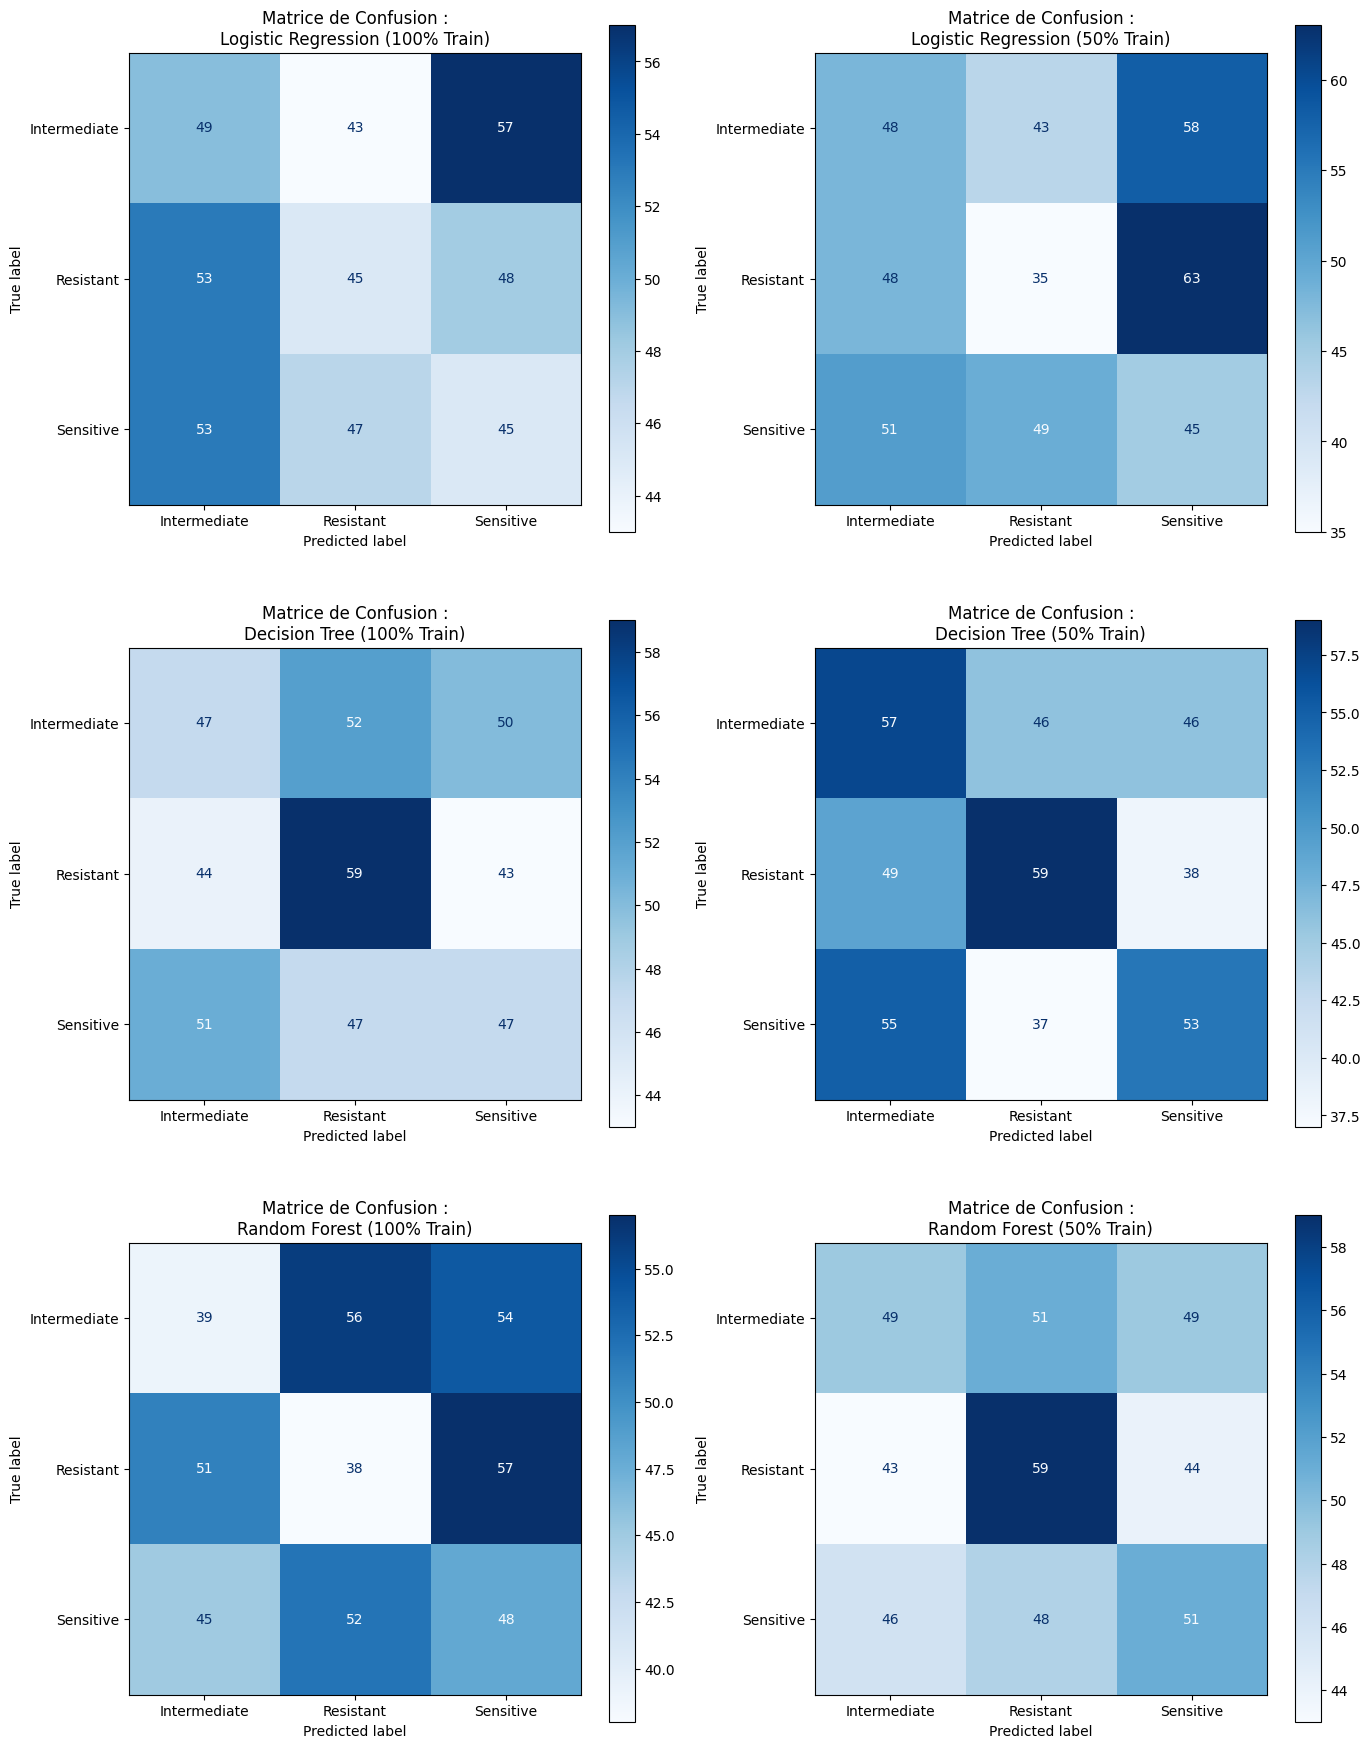

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Dictionnaire des modèles déjà entraînés et enregistrés
models_to_evaluate = {
    'Logistic Regression (100% Train)': pipelines_100['Logistic Regression'],
    'Logistic Regression (50% Train)': pipelines_50['Logistic Regression'],
    'Decision Tree (100% Train)': pipelines_100['Decision Tree'],
    'Decision Tree (50% Train)': pipelines_50['Decision Tree'],
    'Random Forest (100% Train)': pipelines_100['Random Forest'],
    'Random Forest (50% Train)': pipelines_50['Random Forest']
}

# Classes cibles ordonnées
class_labels = sorted(Y_test.unique())

print("=== VÉRIFICATION DES ACCURACIES DIRECTES ===")
for name, model in models_to_evaluate.items():
    # Calcul des prédictions en direct sur le même X_test (440 obs)
    predictions = model.predict(X_test)
    # Calcul direct de l'accuracy
    direct_acc = accuracy_score(Y_test, predictions)
    print(f"{name:35} | Accuracy calculée : {direct_acc:.4f}")

# Tracé des 6 matrices de confusion
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.ravel()

for i, (name, model) in enumerate(models_to_evaluate.items()):
    predictions = model.predict(X_test)
    cm = confusion_matrix(Y_test, predictions, labels=class_labels)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(f"Matrice de Confusion :\n{name}")

plt.tight_layout()
plt.show()

### 📊 Analyse et Interprétation des Matrices de Confusion

Chaque matrice de confusion croise les classes réelles (**True label**) et les classes prédites (**Predicted label**) pour les trois catégories : `Intermediate`, `Resistant` et `Sensitive`.

#### 1. Interprétation des axes
* **La diagonale principale** (du haut gauche au bas droit) représente les **vrais positifs** (prédictions correctes) pour chaque classe.
* **Les éléments hors diagonale** représentent les erreurs de classification.

#### 2. Comparaison des configurations (100% vs 50% d'entraînement)
* **Régression Logistique :**
  * À **100%**, l'exactitude globale est de **31.59%**. Elle montre une répartition des prédictions assez dispersée.
  * À **50%**, l'exactitude diminue à **29.09%**. On constate une légère dégradation sur la diagonale.
* **Arbre de Décision (Decision Tree) :**
  * À **100%**, l'exactitude est de **34.77%**.
  * À **50%**, l'exactitude monte à **38.41%**. Bien qu'un échantillon plus grand soit généralement préférable, les arbres de décision sont très sensibles aux variations spécifiques des données d'entraînement.
* **Forêt Aléatoire (Random Forest) :**
  * À **100%**, l'exactitude est de **28.86%**.
  * À **50%**, l'exactitude est de **36.14%**. La réduction de la taille des données combinée au sous-échantillonnage de l'algorithme a ici modifié les frontières de décision de manière à mieux s'aligner sur cet ensemble de test particulier.